In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## hyperparameter-surface

**Figure 2: Validation loss of our model over a 13 × 13 sweep of learning rate and weight decay.** Both axes are on a log scale, contours are spaced 0.5 apart with all losses above 4.0 in the darkest band, and the star marks the lowest validation loss in the sweep. The loss is lowest, 1.91, at learning rate 3.2e-4 and weight decay 5.6e-3, and training diverges at the largest learning rates, where the loss climbs back to 3.8–4.6 at learning rate 0.01.

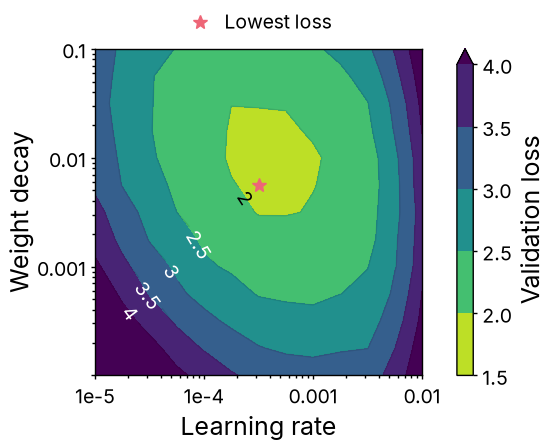

In [2]:
with open("../data/hyperparameter-surface.json") as f:
    data = json.load(f)
learning_rate = np.array(data["learning_rate"])
weight_decay = np.array(data["weight_decay"])
val_loss = np.array(data["val_loss"])
X, Y = np.meshgrid(learning_rate, weight_decay)

fig, ax = plt.subplots(figsize=(2.75, 2.75))
ax.set_xscale("log")
ax.set_yscale("log")
cs = ax.contourf(X, Y, val_loss, levels=np.arange(1.5, 4.01, 0.5), cmap="viridis_r", extend="max")
lines = ax.contour(X, Y, val_loss, levels=cs.levels, colors=colors["ink"], alpha=0.1)

# label each level once, where it crosses the diagonal from the best run to the low-lr, low-wd corner
path = [(7, 6), (6, 5), (5, 4), (4, 3), (3, 2), (2, 1), (1, 0), (0, 0)]
path_loss = [val_loss[i, j] for i, j in path]
steps = np.arange(len(path))
positions = []
for level in cs.levels[1:]:
    t = np.interp(level, path_loss, steps)
    lr = 10 ** np.interp(t, steps, [np.log10(learning_rate[j]) for i, j in path])
    wd = 10 ** np.interp(t, steps, [np.log10(weight_decay[i]) for i, j in path])
    positions.append((lr, wd))
labels = ax.clabel(lines, fmt="%.2g", manual=positions)
for t in labels:
    t.set_alpha(1)
    t.set_color(text_color(cs.cmap(cs.norm(float(t.get_text())))))

i, j = np.unravel_index(val_loss.argmin(), val_loss.shape)
ax.plot(learning_rate[j], weight_decay[i], "*", color=colors["ours"], markerfacecolor=colors["ours"],
        markersize=2 * plt.rcParams["lines.markersize"], linestyle="none", label="Lowest loss")

ax.set_xticks([1e-5, 1e-4, 1e-3, 1e-2], labels=["1e-5", "1e-4", "0.001", "0.01"])
ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1], labels=["", "0.001", "0.01", "0.1"])
ax.grid(False)
ax.set_xlabel("Learning rate")
ax.set_ylabel("Weight decay")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=1, frameon=False)
fig.colorbar(cs, ax=ax, label="Validation loss")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/hyperparameter-surface.pdf")
fig.savefig("../outputs/hyperparameter-surface.png")
plt.show()